In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    roc_auc_score,
    recall_score,
    confusion_matrix,
    classification_report
)

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold,cross_validate

from xgboost import XGBClassifier


In [37]:
columns = [
    "checking_status", "duration", "credit_history", "purpose",
    "credit_amount", "savings_status", "employment",
    "installment_rate", "personal_status_sex", "other_debtors",
    "residence_since", "property", "age", "other_installment_plans",
    "housing", "existing_credits", "job", "num_dependents",
    "telephone", "foreign_worker", "target"
]

df = pd.read_csv(
    "/content/german.data",
    sep=r"\s+",
    header=None,
    names=columns
)

In [38]:
X= df.drop("target",axis=1)
y = df["target"]

X_test,X_train ,y_test,y_train = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y

)

In [39]:
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

In [40]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [41]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )

}

In [42]:
results = []

for name, classifier in models.items():
    print("Evaluating:", name)

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    class_2_index = list(model.classes_).index(2)
    y_prob = model.predict_proba(X_test)[:, class_2_index]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=2, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=2, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label=2, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == 2).astype(int), y_prob
        )
    })

results_df = pd.DataFrame(results)
print("\nMODEL COMPARISON")
print(results_df.round(3).to_string(index=False))

Evaluating: Logistic Regression
Evaluating: Decision Tree
Evaluating: Random Forest

MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression     0.728      0.562   0.412     0.476    0.734
      Decision Tree     0.666      0.445   0.454     0.449    0.606
      Random Forest     0.732      0.627   0.267     0.374    0.758


In [43]:
from sklearn.metrics import confusion_matrix

for name, classifier in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"\n{name}")
    print("Rows = actual, columns = predicted")
    print("Class order:", model.classes_)
    print(confusion_matrix(y_test, y_pred, labels=[1, 2]))


Logistic Regression
Rows = actual, columns = predicted
Class order: [1 2]
[[483  77]
 [141  99]]

Decision Tree
Rows = actual, columns = predicted
Class order: [1 2]
[[428 132]
 [135 105]]

Random Forest
Rows = actual, columns = predicted
Class order: [1 2]
[[522  38]
 [176  64]]


In [44]:
print("Full dataset:", df.shape)
print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Full dataset: (1000, 21)
Training features: (200, 20)
Test features: (800, 20)
Training labels: (200,)
Test labels: (800,)


In [45]:
from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Training features: (800, 20)
Test features: (200, 20)
Training labels: (800,)
Test labels: (200,)


In [46]:

results = []

for name, classifier in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    class_2_index = list(model.classes_).index(2)
    y_prob = model.predict_proba(X_test)[:, class_2_index]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=2, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=2, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label=2, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == 2).astype(int), y_prob
        )
    })

    print(f"\n{name}")
    print("Confusion matrix (actual rows, predicted columns):")
    print(confusion_matrix(y_test, y_pred, labels=[1, 2]))

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(results_df.round(3).to_string(index=False))



Logistic Regression
Confusion matrix (actual rows, predicted columns):
[[124  16]
 [ 28  32]]

Decision Tree
Confusion matrix (actual rows, predicted columns):
[[94 46]
 [34 26]]

Random Forest
Confusion matrix (actual rows, predicted columns):
[[127  13]
 [ 35  25]]

MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression      0.78      0.667   0.533     0.593    0.804
      Decision Tree      0.60      0.361   0.433     0.394    0.552
      Random Forest      0.76      0.658   0.417     0.510    0.784


USING XGBOOST


In [47]:
y_train_xgb = (y_train == 2).astype(int)
y_test_xgb = (y_test == 2).astype(int)

# Build the pipeline
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train XGBoost using 0/1 labels
xgb_model.fit(X_train, y_train_xgb)

# Predictions: 0 = good risk, 1 = bad risk
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Results")
print("-------------------")
print("Accuracy:", round(
    accuracy_score(y_test_xgb, y_pred_xgb), 3
))
print("Precision:", round(
    precision_score(y_test_xgb, y_pred_xgb, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test_xgb, y_pred_xgb, zero_division=0), 3
))
print("F1-Score:", round(
    f1_score(y_test_xgb, y_pred_xgb, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_xgb, y_prob_xgb), 3
))

print("\nConfusion Matrix")
print("Rows = actual, columns = predicted")
print("Class order: [0=good risk, 1=bad risk]")
print(confusion_matrix(y_test_xgb, y_pred_xgb, labels=[0, 1]))

XGBoost Results
-------------------
Accuracy: 0.76
Precision: 0.65
Recall: 0.433
F1-Score: 0.52
ROC-AUC: 0.796

Confusion Matrix
Rows = actual, columns = predicted
Class order: [0=good risk, 1=bad risk]
[[126  14]
 [ 34  26]]


Tuning XGBoost

In [48]:
y_train_xgb = (y_train == 2).astype(int)
y_test_xgb = (y_test == 2).astype(int)


xgb_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ("classifier",XGBClassifier(
        n_jobs=1,
        objective ="binary:logistic",
        random_state=42,
        eval_metric="logloss"
    ))
])

In [49]:
param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [2, 3, 4],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0]
}

In [50]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)

In [51]:
random_search.fit(X_train, y_train_xgb)

print("Best Cross-Validation F1-Score:",
      round(random_search.best_score_, 4))

print("\nBest Hyperparameters:")
print(random_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Cross-Validation F1-Score: 0.5487

Best Hyperparameters:
{'classifier__subsample': 0.8, 'classifier__n_estimators': 300, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 1.0}


In [52]:

# Get the best model found during tuning
best_xgb_model = random_search.best_estimator_

# Make predictions on the untouched test set
y_pred_tuned = best_xgb_model.predict(X_test)
y_prob_tuned = best_xgb_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Tuned XGBoost Model Evaluation")
print("-" * 35)

print("Accuracy:",
      round(accuracy_score(y_test_xgb, y_pred_tuned), 4))

print("Precision:",
      round(precision_score(y_test_xgb, y_pred_tuned, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test_xgb, y_pred_tuned, zero_division=0), 4))

print("F1-Score:",
      round(f1_score(y_test_xgb, y_pred_tuned, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test_xgb, y_prob_tuned), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_xgb, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(
    y_test_xgb,
    y_pred_tuned,
    target_names=["Good Risk", "Bad Risk"],
    zero_division=0
))


Tuned XGBoost Model Evaluation
-----------------------------------
Accuracy: 0.785
Precision: 0.6735
Recall: 0.55
F1-Score: 0.6055
ROC-AUC: 0.8031

Confusion Matrix:
[[124  16]
 [ 27  33]]

Classification Report:
              precision    recall  f1-score   support

   Good Risk       0.82      0.89      0.85       140
    Bad Risk       0.67      0.55      0.61        60

    accuracy                           0.79       200
   macro avg       0.75      0.72      0.73       200
weighted avg       0.78      0.79      0.78       200



Comparison table

In [53]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state =42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
}

In [67]:
results = []
confusion_matrices = {}

y_test_binary = (y_test == 2).astype(int)

for name,classifier in baseline_models.items():


  model = Pipeline([
      ("preprocessor",clone(preprocessor)),
      ("classifier",classifier)
  ])

  model.fit(X_train,y_train)

  predictions = model.predict(X_test)


  bad_risk_index = list(model.classes_).index(2)
  probabilities = model.predict_proba(X_test)[:,bad_risk_index]

  results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label=2, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label=2, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, pos_label=2, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_binary, probabilities)
    })


  confusion_matrices[name]=confusion_matrix(
        y_test, predictions, labels=[1, 2]
    )

In [68]:
tuned_predictions = best_xgb_model.predict(X_test)
tuned_probabilities = best_xgb_model.predict_proba(X_test)[:, 1]


tuned_predictions_original = np.where(
    tuned_predictions == 1, 2, 1
)

results.append({
    "Model": "Tuned XGBoost",
    "Accuracy": accuracy_score(y_test_binary, tuned_predictions),
    "Precision": precision_score(
        y_test_binary, tuned_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_binary, tuned_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test_binary, tuned_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test_binary, tuned_probabilities)
})

confusion_matrices["Tuned XGBoost"] = confusion_matrix(
    y_test, tuned_predictions_original, labels=[1, 2]
)


In [69]:
comparison_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"
]

comparison_df[metric_columns] = comparison_df[metric_columns].round(4)

comparison_df = comparison_df.sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

print("MODEL COMPARISON")
print("=" * 75)
display(comparison_df)

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned XGBoost,0.785,0.6735,0.5500,0.6055,0.8031
1,Logistic Regression,0.780,0.6667,0.5333,0.5926,0.8040
2,Random Forest,0.760,0.6579,0.4167,0.5102,0.7837
3,Decision Tree,0.630,0.3793,0.3667,0.3729,0.5548


In [70]:
for name, matrix in confusion_matrices.items():
    print(f"\n{name}")
    print("Rows = actual [Good Risk, Bad Risk]")
    print("Columns = predicted [Good Risk, Bad Risk]")
    print(matrix)



Logistic Regression
Rows = actual [Good Risk, Bad Risk]
Columns = predicted [Good Risk, Bad Risk]
[[124  16]
 [ 28  32]]

Decision Tree
Rows = actual [Good Risk, Bad Risk]
Columns = predicted [Good Risk, Bad Risk]
[[104  36]
 [ 38  22]]

Random Forest
Rows = actual [Good Risk, Bad Risk]
Columns = predicted [Good Risk, Bad Risk]
[[127  13]
 [ 35  25]]

Tuned XGBoost
Rows = actual [Good Risk, Bad Risk]
Columns = predicted [Good Risk, Bad Risk]
[[124  16]
 [ 27  33]]


In [71]:
y_train_binary = (y_train == 2).astype(int)

models_cv = {
    "Logistic Regression": LogisticRegression(max_iter=2000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Tuned XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )
}


In [73]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "f1": "f1",
    "recall": "recall",
    "roc_auc": "roc_auc"
}


In [76]:
cv_results = []

for name, classifier in models_cv.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train_binary,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "Mean F1": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),
        "Mean Recall": scores["test_recall"].mean(),
        "Recall Std": scores["test_recall"].std(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean()
    })

In [77]:
cv_comparison = pd.DataFrame(cv_results)

metric_columns = [
    "Mean F1", "F1 Std",
    "Mean Recall", "Recall Std",
    "Mean ROC-AUC"
]

cv_comparison[metric_columns] = (
    cv_comparison[metric_columns].round(4)
)

cv_comparison = cv_comparison.sort_values(
    by="Mean F1",
    ascending=False
).reset_index(drop=True)

print("5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 65)
display(cv_comparison)


5-FOLD CROSS-VALIDATION RESULTS


,Model,Mean F1,F1 Std,Mean Recall,Recall Std,Mean ROC-AUC
0,Tuned XGBoost,0.5487,0.0416,0.5042,0.0595,0.7911
1,Logistic Regression,0.4940,0.1011,0.4333,0.1098,0.7706
2,Decision Tree,0.4688,0.0316,0.4708,0.0429,0.6202
3,Random Forest,0.4687,0.0833,0.3708,0.0806,0.7867


Feature Importance

In [80]:
fitted_preprocessor = best_xgb_model.named_steps["preprocessor"]
fitted_xgb = best_xgb_model.named_steps["classifier"]


feature_names = fitted_preprocessor.get_feature_names_out()
importance_scores = fitted_xgb.feature_importances_


importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})


TOP 15 FEATURES — TUNED XGBOOST


,Feature,Importance
0,cat__checking_status_A14,0.0802
1,cat__property_A124,0.0373
2,cat__savings_status_A61,0.0343
3,cat__credit_history_A31,0.0296
4,cat__credit_history_A34,0.0275
5,cat__other_installment_plans_A141,0.0261
6,cat__employment_A72,0.0256
7,cat__employment_A71,0.0226
8,cat__purpose_A46,0.0217
9,cat__checking_status_A11,0.0211


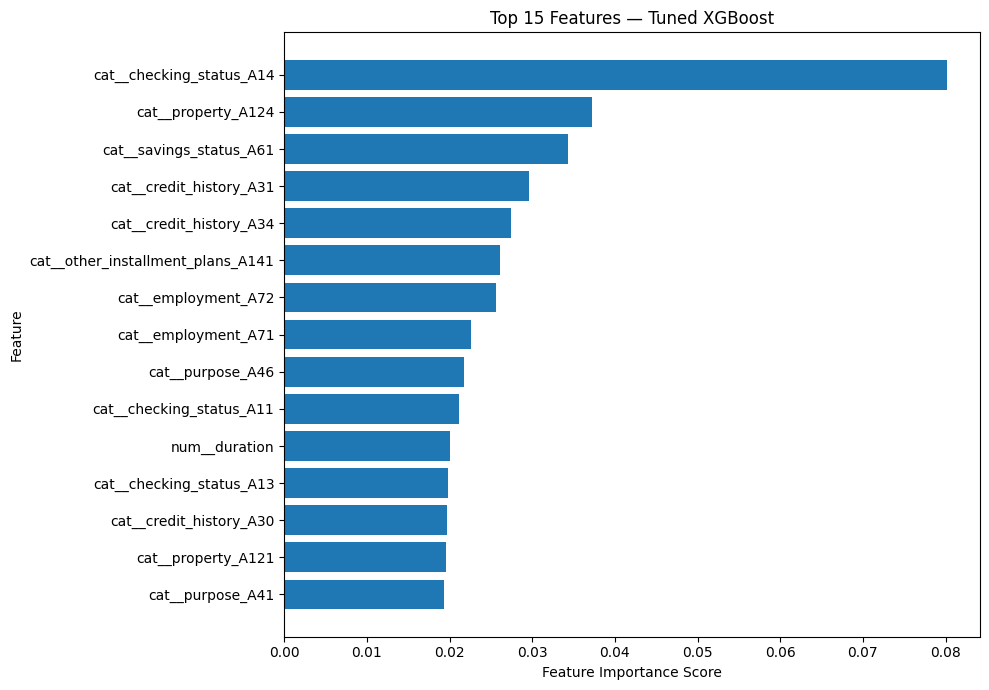

In [82]:
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


print("TOP 15 FEATURES — TUNED XGBOOST")
print("=" * 45)
display(importance_df.head(15).round(4))


top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)



plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance Score")
plt.ylabel("Feature")
plt.title("Top 15 Features — Tuned XGBoost")
plt.tight_layout()
plt.show()


In [83]:

import joblib
import json
import os


os.makedirs("credit_scoring_artifacts", exist_ok=True)


model_path = "credit_scoring_artifacts/credit_scoring_pipeline.joblib"

joblib.dump(best_xgb_model, model_path)


metadata = {
    "project": "Credit Scoring Model",
    "model": "Tuned XGBoost",
    "dataset": "German Credit Dataset",
    "target_mapping": {
        "1": "Good Risk",
        "2": "Bad Risk",
        "xgboost_0": "Good Risk",
        "xgboost_1": "Bad Risk"
    },
    "best_hyperparameters": {
        key: (
            value.item()
            if hasattr(value, "item")
            else value
        )
        for key, value in random_search.best_params_.items()
    },
    "cross_validation": {
        "folds": 5,
        "mean_f1": 0.5487,
        "f1_std": 0.0416,
        "mean_recall": 0.5042,
        "mean_roc_auc": 0.7911
    },
    "test_metrics": {
        "accuracy": 0.785,
        "precision": 0.6735,
        "recall": 0.5500,
        "f1_score": 0.6055,
        "roc_auc": 0.8031
    },
    "important_note": (
        "Predicts good/bad credit risk; does not calculate "
        "an official credit score. Metrics are from one "
        "held-out test split."
    )
}

metadata_path = "credit_scoring_artifacts/model_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)


importance_path = "credit_scoring_artifacts/feature_importance.csv"

importance_df.to_csv(importance_path, index=False)


print("MODEL ARTIFACTS SAVED")
print("-" * 35)

for file_path in [model_path, metadata_path, importance_path]:
    print(f"{file_path}: {os.path.getsize(file_path):,} bytes")

print("\nBest model saved:", os.path.exists(model_path))


MODEL ARTIFACTS SAVED
-----------------------------------
credit_scoring_artifacts/credit_scoring_pipeline.joblib: 352,830 bytes
credit_scoring_artifacts/model_metadata.json: 971 bytes
credit_scoring_artifacts/feature_importance.csv: 2,002 bytes

Best model saved: True


In [84]:
import shutil

shutil.make_archive(
    "credit_scoring_artifacts",
    "zip",
    "credit_scoring_artifacts"
)

from google.colab import files
files.download("credit_scoring_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>